# GreenCampus AI – Exploratory Data Analysis

## 1. Introduction

Exploratory Data Analysis (EDA) is performed to understand campus
resource-consumption patterns before applying AI models.

The analysis focuses on electricity, water, waste, occupancy,
temperature, buildings, working days, and event days.

## 2. Dataset Overview

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


df = pd.read_csv("cleaned_campus_sustainability_data.csv")

df["Date"] = pd.to_datetime(df["Date"])

print("Dataset loaded successfully")
print("Shape: ", df.shape)

df.head()

Dataset loaded successfully
Shape:  (1825, 10)


,Date,Building,Building_Type,Occupancy,Electricity_kWh,Water_Litres,Waste_kg,Temperature_C,Working_Day,Event_Day
0,2025-07-01,Block A,Academic,444,1437.09,8384.17,47.61,28.0,Yes,No
1,2025-07-01,Block B,Academic,269,1091.78,4583.04,23.77,28.0,Yes,No
2,2025-07-01,Block C,Laboratory,186,707.71,3556.96,22.42,28.0,Yes,No
3,2025-07-01,Library,Library,230,760.70,4039.62,24.38,28.0,Yes,No
4,2025-07-01,Hostel,Hostel,555,1679.32,9611.07,54.21,28.0,Yes,No


## 3. Descriptive Statistics

In [2]:
df.describe()

,Date,Occupancy,Electricity_kWh,Water_Litres,Waste_kg,Temperature_C
count,1825,1825.000000,1825.000000,1825.000000,1825.000000,1825.000000
mean,2025-12-30 00:00:00.000000256,262.682192,1035.099419,4586.356444,26.833726,27.893151
min,2025-07-01 00:00:00,10.000000,214.340000,500.000000,2.000000,15.200000
25%,2025-09-30 00:00:00,138.000000,699.480000,1678.740000,13.610000,24.600000
50%,2025-12-30 00:00:00,250.000000,952.750000,4510.550000,25.030000,28.100000
75%,2026-03-31 00:00:00,399.000000,1394.500000,7092.600000,39.800000,31.000000
max,2026-06-30 00:00:00,664.000000,2176.090000,12456.550000,83.730000,40.600000
std,NaN,153.906310,433.863039,2944.435822,16.379536,4.710091


## 4. Total Resource Consumption

In [3]:
total_electricity = df["Electricity_kWh"].sum()
total_water = df["Water_Litres"].sum()
total_waste = df["Waste_kg"].sum()

print("Total Electricity: ", round(total_electricity, 2), "kWh")
print("Total Water: ", round(total_water, 2), "Litres")
print("Total Waste: ", round(total_waste, 2), "kg")

Total Electricity:  1889056.44 kWh
Total Water:  8370100.51 Litres
Total Waste:  48971.55 kg


## 5. Building-wise Resource Consumption

#### Building-wise electricity consumption

In [4]:
building_electricity = (df.groupby("Building")["Electricity_kWh"].sum().sort_values(ascending=False))

print(building_electricity)

Building
Hostel     555335.97
Block A    470261.12
Block B    354740.48
Library    290337.06
Block C    218381.81
Name: Electricity_kWh, dtype: float64


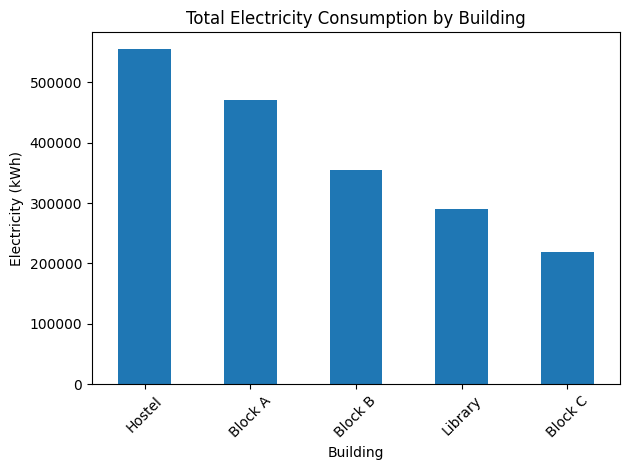

In [5]:
building_electricity.plot(kind="bar")

plt.title("Total Electricity Consumption by Building")
plt.xlabel("Building")
plt.ylabel("Electricity (kWh)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Building wise water consumption

In [6]:
building_water = (df.groupby("Building")["Water_Litres"].sum().sort_values(ascending=False))

print(building_water)

Building
Hostel     2524788.01
Block A    2110579.85
Block B    1550772.33
Library    1267800.55
Block C     916159.77
Name: Water_Litres, dtype: float64


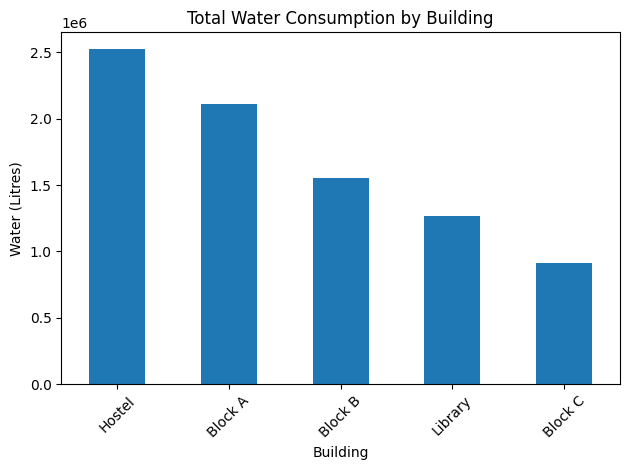

In [7]:
building_water.plot(kind="bar")

plt.title("Total Water Consumption by Building")
plt.xlabel("Building")
plt.ylabel("Water (Litres)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Building wise waste generation

In [8]:
building_waste = (df.groupby("Building")["Waste_kg"].sum().sort_values(ascending=False))

print(building_waste)

Building
Hostel     14874.04
Block A    12378.74
Block B     8993.63
Library     7416.62
Block C     5308.52
Name: Waste_kg, dtype: float64


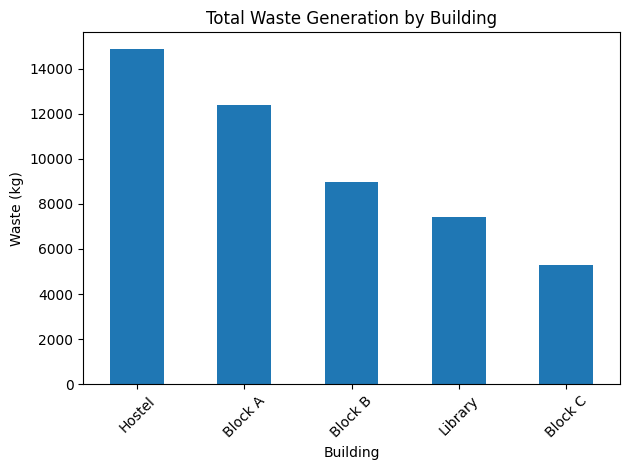

In [9]:
building_waste.plot(kind="bar")

plt.title("Total Waste Generation by Building")
plt.xlabel("Building")
plt.ylabel("Waste (kg)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 6. Monthly Resource Consumption Trends

#### Monthly electricity trend

In [10]:
df["Month"] = df["Date"].dt.to_period("M")

In [11]:
monthly_electricity = (df.groupby("Month")["Electricity_kWh"].sum())

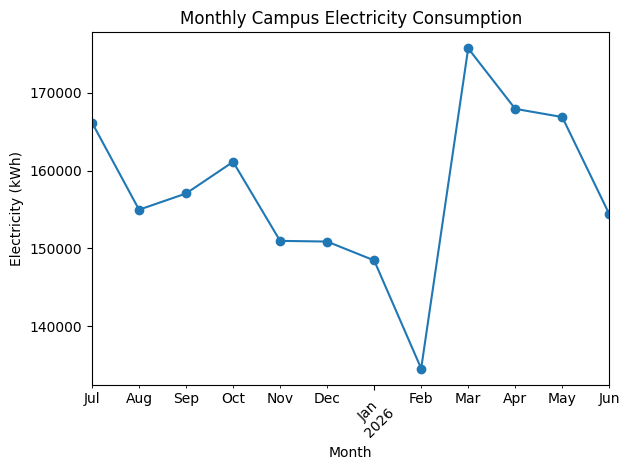

In [12]:
monthly_electricity.plot(kind="line", marker="o")

plt.title("Monthly Campus Electricity Consumption")
plt.xlabel("Month")
plt.ylabel("Electricity (kWh)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Monthly water trend

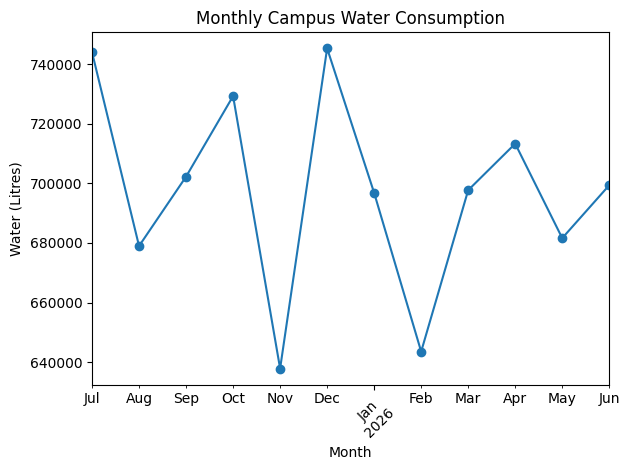

In [13]:
monthly_water = (df.groupby("Month")["Water_Litres"].sum())

monthly_water.plot(kind = "line", marker = "o")
plt.title("Monthly Campus Water Consumption")
plt.xlabel("Month")
plt.ylabel("Water (Litres)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Monthly waste trend

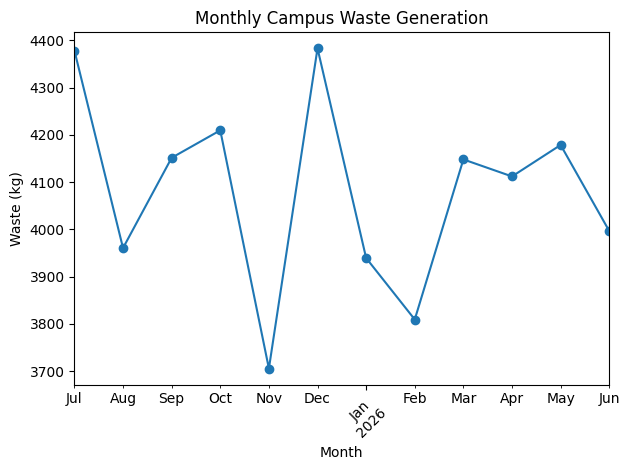

In [14]:
monthly_waste = (df.groupby("Month")["Waste_kg"].sum())

monthly_waste.plot(kind = "line", marker = "o")

plt.title("Monthly Campus Waste Generation")
plt.xlabel("Month")
plt.ylabel("Waste (kg)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 7. Occupancy and Resource Consumption

#### Occupancy vs electricity

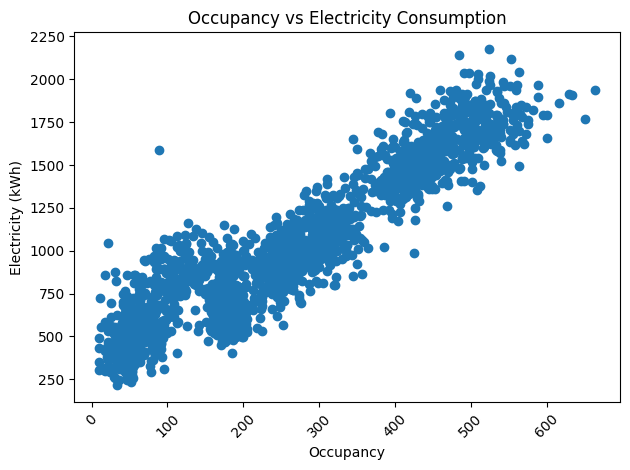

In [15]:
plt.scatter(df["Occupancy"], df["Electricity_kWh"])

plt.title("Occupancy vs Electricity Consumption")
plt.xlabel("Occupancy")
plt.ylabel("Electricity (kWh)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
df["Occupancy"].corr(df["Electricity_kWh"])

np.float64(0.9254854519873393)

#### Occupancy vs water

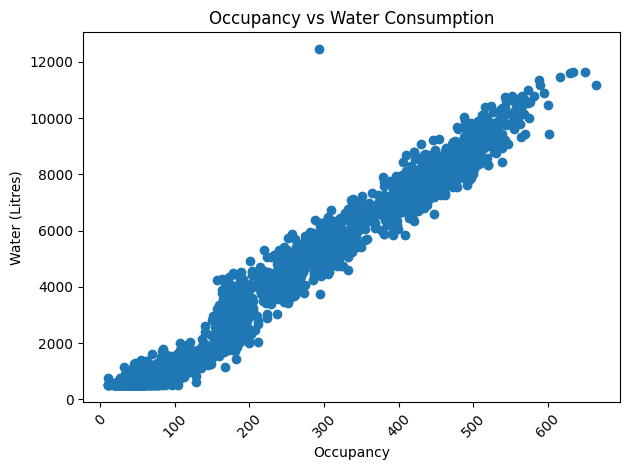

In [17]:
plt.scatter(df["Occupancy"], df["Water_Litres"])

plt.title("Occupancy vs Water Consumption")
plt.xlabel("Occupancy")
plt.ylabel("Water (Litres)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [18]:
df["Occupancy"].corr(df["Water_Litres"])

np.float64(0.9821955661336736)

## 8. Temperature and Electricity Consumption

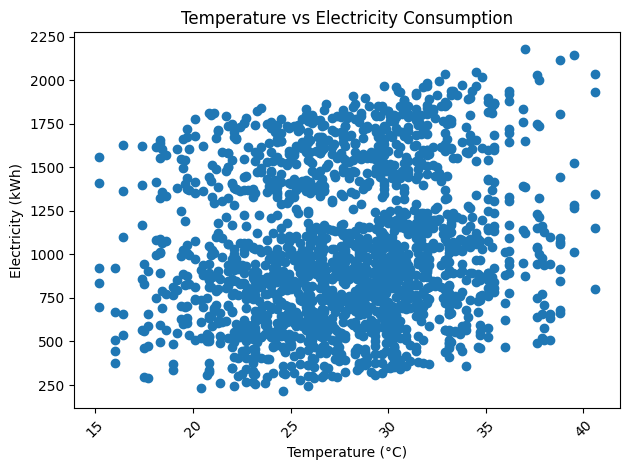

In [19]:
plt.scatter(df["Temperature_C"],df["Electricity_kWh"])

plt.title("Temperature vs Electricity Consumption")
plt.xlabel("Temperature (°C)")
plt.ylabel("Electricity (kWh)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
df["Temperature_C"].corr(df["Electricity_kWh"])

np.float64(0.1590357640903063)

## 9. Working Day vs Non-Working Day Analysis

In [21]:
working_day_analysis = (df.groupby("Working_Day")[["Electricity_kWh", "Water_Litres", "Waste_kg"]].mean())

working_day_analysis

,Electricity_kWh,Water_Litres,Waste_kg
Working_Day,,,
No,650.737692,1019.278212,8.563962
Yes,1188.255050,6007.720950,34.113632


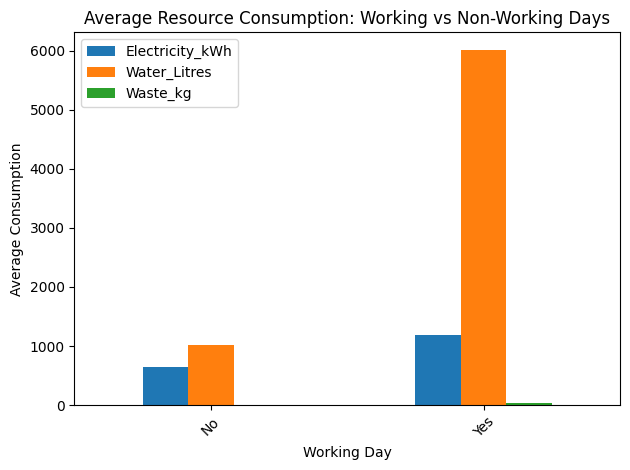

In [22]:
working_day_analysis.plot(kind="bar")
plt.title("Average Resource Consumption: Working vs Non-Working Days")
plt.xlabel("Working Day")
plt.ylabel("Average Consumption")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 10. Event Day Analysis

In [23]:
event_analysis = (df.groupby("Event_Day")[["Occupancy", "Electricity_kWh", "Water_Litres", "Waste_kg"]].mean())
event_analysis

,Occupancy,Electricity_kWh,Water_Litres,Waste_kg
Event_Day,,,,
No,259.137572,1031.269775,4520.228613,25.966699
Yes,327.231579,1104.839263,5790.579053,42.622737


#### Find the highest consumption records

In [24]:
#highest electricity
df.nlargest(10, "Electricity_kWh")
[["Date", "Building", "Electricity_kWh", "Occupancy", "Temperature_C"]]

#highest water
df.nlargest(10, "Water_Litres")
[[ "date", "Building", "Water_Litres", "Occupancy"
]]

#highest waste
df.nlargest(10, "Waste_kg")[
    ["Date", "Building", "Waste_kg", "Occupancy", "Event_Day"]
]

,Date,Building,Waste_kg,Occupancy,Event_Day
139,2025-07-28,Hostel,83.73,630,Yes
209,2025-08-11,Hostel,81.96,634,Yes
1399,2026-04-06,Hostel,81.96,650,Yes
1329,2026-03-23,Hostel,80.38,664,Yes
1554,2026-05-07,Hostel,79.26,601,Yes
334,2025-09-05,Hostel,76.26,560,Yes
879,2025-12-23,Hostel,76.13,568,Yes
469,2025-10-02,Hostel,75.76,616,Yes
1618,2026-05-20,Library,74.97,258,No
330,2025-09-05,Block A,73.77,538,Yes


#### Checking out three intentional anomalies

In [25]:
anomaly_examples = df[((df["Date"] == "2026-02-15") & (df["Building"] == "Block A")) | ((df["Date"] == "2026-04-10") & (df["Building"] == "Block B")) | ((df["Date"] == "2026-05-20") & (df["Building"] == "Library"))]
anomaly_examples

,Date,Building,Building_Type,Occupancy,Electricity_kWh,Water_Litres,Waste_kg,Temperature_C,Working_Day,Event_Day,Month
1145,2026-02-15,Block A,Academic,89,1584.73,553.61,6.95,25.2,No,No,2026-02
1416,2026-04-10,Block B,Academic,294,1171.87,12456.55,27.65,27.7,Yes,No,2026-04
1618,2026-05-20,Library,Library,258,1094.30,4833.74,74.97,36.2,Yes,No,2026-05


## 11. Correlation Analysis

In [26]:
print("======== EDA Summary ========")

print("\nDataset shape:")
print(df.shape)

print("\nTotal electricity (kWh):")
print(round(df["Electricity_kWh"].sum(), 2))

print("\nTotal Water (Litres):")
print(round(df["Water_Litres"].sum(), 2))

print("\nTotal Waste (kg):")
print(round(df["Waste_kg"].sum(), 2))

print("\nAverage occupancy:")
print(round(df["Occupancy"].mean(), 2))

print("\nElectricity-Occupancy correlation:")
print(round(df["Occupancy"].corr(df["Electricity_kWh"]), 3))

print("\nWater-Occupancy correlation:")
print(round(df["Occupancy"].corr(df["Water_Litres"]), 3))

print("\nTemperature-Electricity correlation:")
print(round(df["Temperature_C"].corr(df["Electricity_kWh"]), 3))

======== EDA Summary ========

Dataset shape:
(1825, 11)

Total electricity (kWh):
1889056.44

Total Water (Litres):
8370100.51

Total Waste (kg):
48971.55

Average occupancy:
262.68

Electricity-Occupancy correlation:
0.925

Water-Occupancy correlation:
0.982

Temperature-Electricity correlation:
0.159


## 12. EDA Summary

The exploratory analysis helps identify important patterns and
relationships in campus resource consumption.

These observations are used as supporting information for the
subsequent AI-based analysis.